In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = pd.read_csv("household_power_consumption.txt", sep=";", na_values=['?'])

ds['Date'] = pd.to_datetime(ds['Date'], format='%d/%m/%Y')
ds['Time'] = pd.to_datetime(ds['Time'], format='%H:%M:%S')

ds['Month'] = ds['Date'].dt.month
ds['Day_of_Week'] = ds['Date'].dt.dayofweek
ds['Hour'] = ds['Time'].dt.hour

ds = ds.drop(['Date', 'Time'], axis=1)
print(ds.head())

   Global_active_power  Global_reactive_power  Voltage  Global_intensity  \
0                4.216                  0.418   234.84              18.4   
1                5.360                  0.436   233.63              23.0   
2                5.374                  0.498   233.29              23.0   
3                5.388                  0.502   233.74              23.0   
4                3.666                  0.528   235.68              15.8   

   Sub_metering_1  Sub_metering_2  Sub_metering_3  Month  Day_of_Week  Hour  
0             0.0             1.0            17.0     12            5    17  
1             0.0             1.0            16.0     12            5    17  
2             0.0             2.0            17.0     12            5    17  
3             0.0             1.0            17.0     12            5    17  
4             0.0             1.0            17.0     12            5    17  


In [3]:
ds.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Month,Day_of_Week,Hour
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.075259e+06,2.075259e+06,2.075259e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00,6.450359e+00,2.998909e+00,1.150076e+01
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00,3.415762e+00,2.000064e+00,6.922227e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00,1.000000e+00,6.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00,6.000000e+00,3.000000e+00,1.200000e+01
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,9.000000e+00,5.000000e+00,1.800000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01,1.200000e+01,6.000000e+00,2.300000e+01


In [4]:
def prepare_electricitydata(ds, target):
    all_targets = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
    
    if target not in all_targets:
        raise ValueError(f"Oops! Target must be one of: {all_targets}")
        
    X = ds.drop(columns=all_targets).copy()
    y = ds[target].values
    return X, y   

# --------------------------- Scrapping missing data ---------------------------
# ds_clean = ds.dropna().copy()
# X_clean, y_clean = prepare_electricitydata(ds_clean, target='Sub_metering_1')

X, y = prepare_electricitydata(ds, target='Sub_metering_1')
print(X.head())

   Global_active_power  Global_reactive_power  Voltage  Global_intensity  \
0                4.216                  0.418   234.84              18.4   
1                5.360                  0.436   233.63              23.0   
2                5.374                  0.498   233.29              23.0   
3                5.388                  0.502   233.74              23.0   
4                3.666                  0.528   235.68              15.8   

   Month  Day_of_Week  Hour  
0     12            5    17  
1     12            5    17  
2     12            5    17  
3     12            5    17  
4     12            5    17  


In [5]:
# --------------------------- Handling missing data ---------------------------
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

X_clean = imputer.fit_transform(X)
y_clean = imputer.fit_transform(y.reshape(-1, 1)).flatten()

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.25, random_state=0)

In [6]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()

X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)

# For SVR
# sc_y = StandardScaler()
# y_train_scaled = sc_y.fit_transform(y_train.reshape(-1, 1)).flatten()

In [8]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [9]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg = PolynomialFeatures(degree=4)
X_poly = poly_reg.fit_transform(X_train_scaled)
lin_reg_2 = LinearRegression()
lin_reg_2.fit(X_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
X_test_poly = poly_reg.transform(X_test_scaled)
y_pred = lin_reg_2.predict(X_test_poly)

In [11]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 23.13
R² Score: 0.30


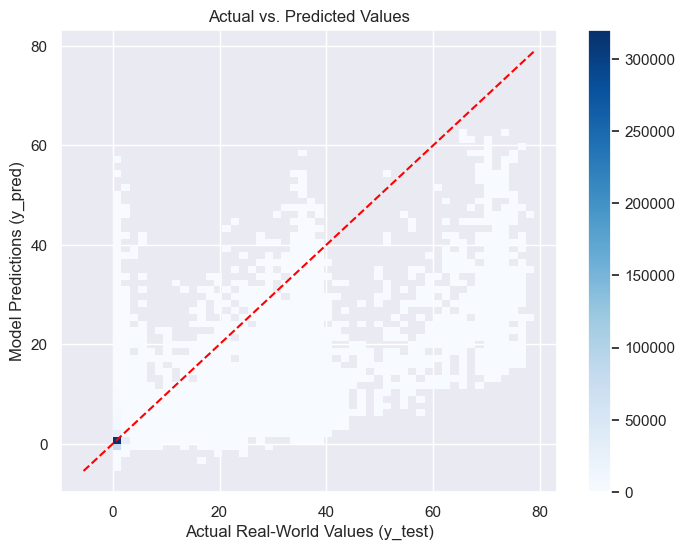

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.histplot(x=y_test, y=y_pred, bins=50, pmax=0.9, cmap="Blues", cbar=True)
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

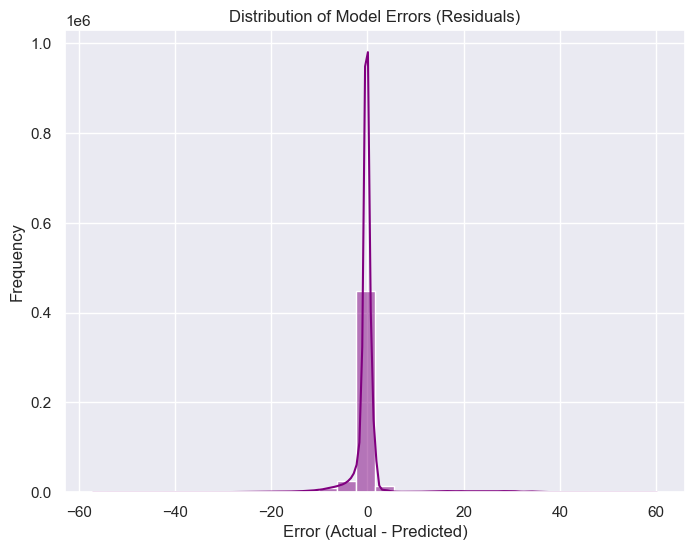

In [17]:
# Calculate the errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()

In [16]:
from sklearn.linear_model import PoissonRegressor
poisson_reg = PoissonRegressor(max_iter=1000, solver='newton-cholesky')
poisson_reg.fit(X_train_scaled, y_train)
y_pred_poisson = poisson_reg.predict(X_test_scaled)

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred_poisson)
r2 = r2_score(y_test, y_pred_poisson)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 55.96
R² Score: -0.48


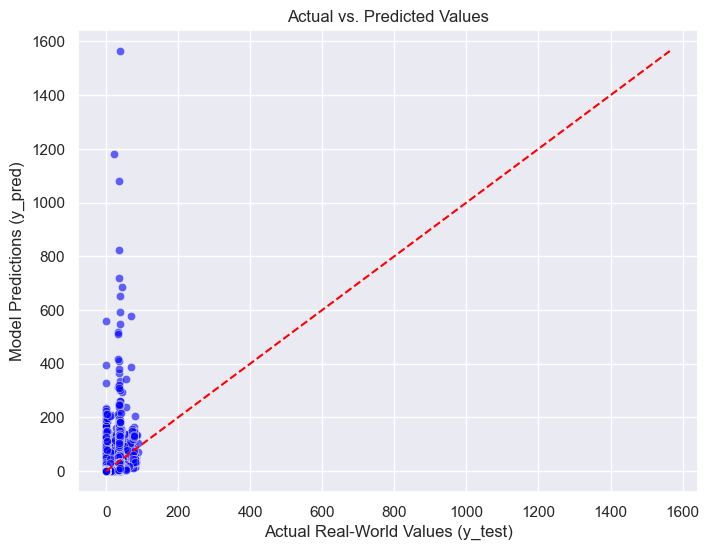

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.scatterplot(x=y_test, y=y_pred_poisson, alpha=0.6, color="blue")
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred_poisson))
max_val = max(max(y_test), max(y_pred_poisson))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

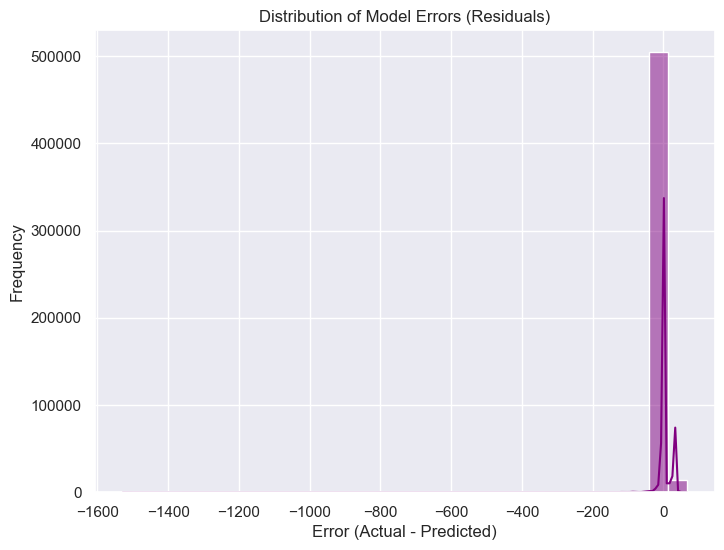

In [10]:
residuals = y_test - y_pred_poisson

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()

In [18]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 4.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [8]:
from lightgbm import LGBMRegressor
lgbm_model = LGBMRegressor(random_state=0)
lgbm_model.fit(X_train_scaled, y_train)

y_pred_lgbm = lgbm_model.predict(X_test_scaled)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.034150 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 949
[LightGBM] [Info] Number of data points in the train set: 1556444, number of used features: 4
[LightGBM] [Info] Start training from score 1.116618


In [11]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred_lgbm)
r2 = r2_score(y_test, y_pred_lgbm)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 22.50
R² Score: 0.41


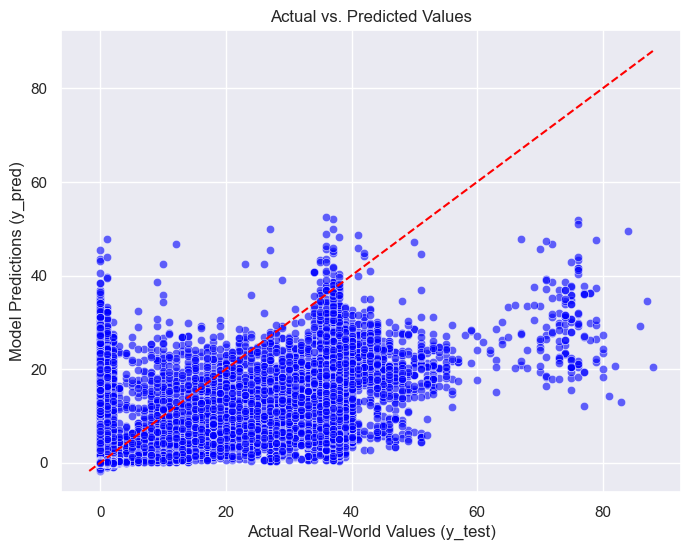

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the histogram using Seaborn
sns.scatterplot(x=y_test, y=y_pred_lgbm, alpha=0.6, color="blue")
# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred_lgbm))
max_val = max(max(y_test), max(y_pred_lgbm))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

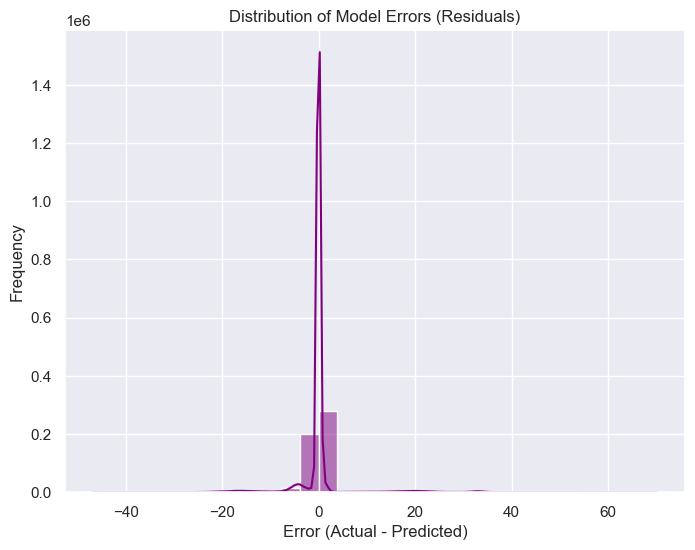

In [14]:
residuals = y_test - y_pred_lgbm

plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()